In [1]:
import pandas as pd 
import numpy as np
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [2]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [3]:
df['category'].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [4]:
df.category.unique()

array(['Hi-Fi Speakers', 'CD, Disc & Tape Players', 'Wearable Technology',
       'Light Bulbs', 'Bathroom Lighting',
       'Heating, Cooling & Air Quality', 'Coffee & Espresso Machines',
       'Lab & Scientific Products', 'Smart Speakers',
       'Motorbike Clothing', 'Motorbike Accessories',
       'Motorbike Batteries', 'Motorbike Boots & Luggage',
       'Motorbike Chassis', 'Handmade Home & Kitchen Products',
       'Hardware', 'Storage & Home Organisation',
       'Fireplaces, Stoves & Accessories', 'PC Gaming Accessories',
       'USB Gadgets', 'Blank Media Cases & Wallets', 'Car & Motorbike',
       'Boys', 'Sports & Outdoors', 'Microphones', 'String Instruments',
       'Karaoke Equipment', 'PA & Stage',
       'General Music-Making Accessories', 'Wind Instruments',
       'Handmade Gifts', 'Fragrances', 'Calendars & Personal Organisers',
       'Furniture & Lighting', 'Computer Printers', 'Ski Goggles',
       'Snowboards', 'Skiing Poles', 'Downhill Ski Boots',
       'Hiki

In [5]:
df.nunique()

uid                  2443651
asin                 2222742
title                2077591
stars                     42
reviews                19446
price                  82916
isBestSeller               2
boughtInLastMonth         25
category                 296
dtype: int64

In [6]:
category1 = df.category.value_counts().round(2).reset_index()
category1

,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Alexa Built-In Devices,107
292,Motorbike Chassis,107
293,Plugs,107
294,Smart Home Security & Lighting,104


In [7]:
port = round(df.category.value_counts('Sports & Outdoors') * 100, 2).reset_index()
port

,category,proportion
0,Sports & Outdoors,34.22
1,Beauty,0.79
2,"Handmade Clothing, Shoes & Accessories",0.79
3,Bath & Body,0.78
4,Birthday Gifts,0.78
...,...,...
291,Alexa Built-In Devices,0.00
292,Motorbike Chassis,0.00
293,Plugs,0.00
294,Smart Home Security & Lighting,0.00


In [8]:
catport = pd.merge (category1, port, on='category')
catport

,category,count,proportion
0,Sports & Outdoors,836265,34.22
1,Beauty,19312,0.79
2,"Handmade Clothing, Shoes & Accessories",19229,0.79
3,Bath & Body,19092,0.78
4,Birthday Gifts,18978,0.78
...,...,...,...
291,Alexa Built-In Devices,107,0.00
292,Motorbike Chassis,107,0.00
293,Plugs,107,0.00
294,Smart Home Security & Lighting,104,0.00


In [9]:
# Frequency Tables: Generate frequency table for the product category. 
# Which are the top 5 most listed product categories? 
top_5cat = catport.sort_values(by='count', ascending=False).head(5)
top_5cat.index = top_5cat.index +1
top_5cat

,category,count,proportion
1,Sports & Outdoors,836265,34.22
2,Beauty,19312,0.79
3,"Handmade Clothing, Shoes & Accessories",19229,0.79
4,Bath & Body,19092,0.78
5,Birthday Gifts,18978,0.78


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

/var/folders/bs/hzz4qdm57z9cct0t_9rdynfr0000gn/T/ipykernel_1514/2354945815.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


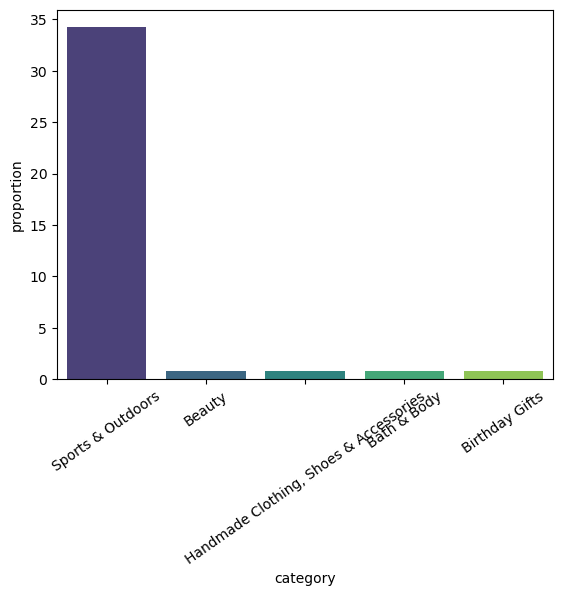

In [11]:
sns.barplot(
    x='category',
    y='proportion',
    data=top_5cat,
    palette='viridis',
)
plt.xticks(rotation=35)
plt.show()

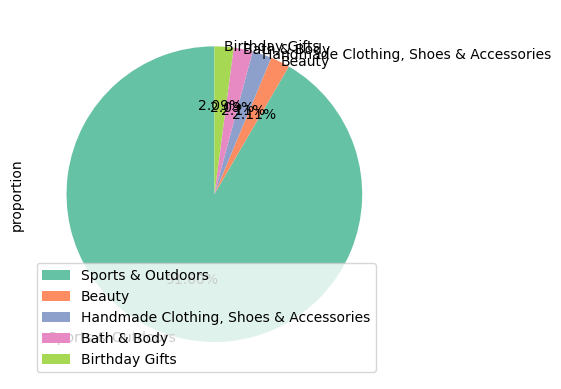

In [12]:
#Does not work with category. 
top_5cat.plot.pie(y='proportion', labels=top_5cat['category'], autopct='%1.2f%%' ,startangle=90, colors=sns.color_palette('Set2'), labeldistance=1)
plt.show()

In [ ]:
# For a subset of top categories, visualize their proportions using a pie chart. 
# Sports and & Outdoors. 

## Part 2: Delving into Product Pricing

Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

**1. Measures of Centrality:**

Calculate the mean, median, and mode for the price of products.

What's the average price point of products listed? How does this compare with the most common price point (mode)?

**2. Measures of Dispersion:**

Determine the variance, standard deviation, range, and interquartile range for product price.

How varied are the product prices? Are there any indicators of a significant spread in prices?

**3. Visualizations:**

Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved.

Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [13]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1.370545e+06,816056.169852,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.152836e+00,2.194865,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,4.806278e+02,5944.124151,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,8.924381e+01,345.608862,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,2.589699e+01,240.483727,0.0,0.00,0.00,0.00,50000.0


In [15]:
df['price'].mean()

89.24380943923663

In [16]:
df['price'].median()

19.09

In [17]:
df['price'].mode()

0    9.99
Name: price, dtype: float64

In [18]:
num = df.select_dtypes(include='number')
num

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


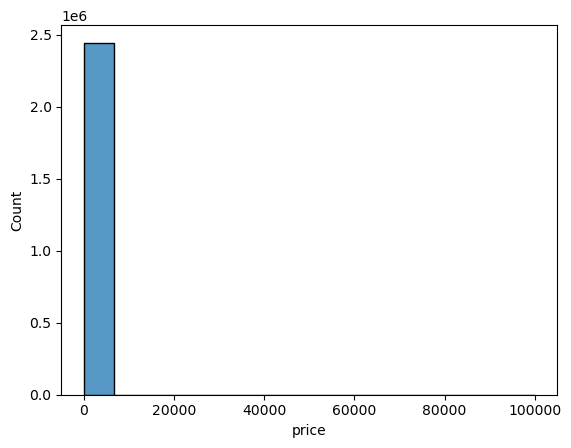

In [19]:
# Porque numeros tan grandes el precio? 
sns.histplot(num.price, bins=15)
plt.show()

In [20]:
df['price'].std()

345.6088617535223

In [21]:
df['price'].var()

119445.4853225653

In [22]:
num.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1370545.35,816056.17,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.15,2.19,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,480.63,5944.12,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,89.24,345.61,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,25.90,240.48,0.0,0.00,0.00,0.00,50000.0


In [23]:
df['price'].quantile([0.5])

0.5    19.09
Name: price, dtype: float64

In [ ]:
"""
High variance (119,445.48) and std (345.60). These confirm that the price vary widely from the mean. The Standard deviation suggest that, on average, prices deviate from the mean by 345.60. 
Large range and high variance indicate diverse pricing structure. 
""" 

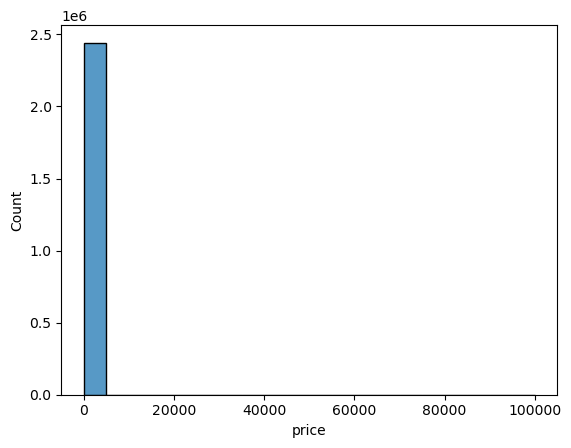

In [24]:
# Porque numeros tan grandes el precio? 
sns.histplot(num.price, bins=20)
plt.show()

In [25]:
num.sort_values(by='price', ascending=False)

,uid,stars,reviews,price,boughtInLastMonth
2008013,2259336,0.0,0,100000.00,0
1987238,2235317,0.0,0,77752.00,0
1905315,2136904,0.0,0,24674.59,0
1408966,1551117,0.0,0,23482.73,0
319555,340285,0.0,0,22933.42,0
...,...,...,...,...,...
794353,855945,4.6,39112,0.00,0
1422882,1565480,5.0,1,0.00,0
1075630,1187147,4.6,3,0.00,0
836136,911439,4.7,2421,0.00,0


In [26]:
df.sort_values(by='price', ascending=False).head(30)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
2008013,2259336,B091F5Y3CT,HB FBA Test Treadmill,0.0,0,100000.00,False,0,Sports & Outdoors
1987238,2235317,B0CDVKNBRV,Générique L.A 350° - I5 11400F - RTX 3050 8G -...,0.0,0,77752.00,False,0,Desktop PCs
1905315,2136904,B0CJSNFYVM,Abaodam decor christmas ornaments Desk Ornamen...,0.0,0,24674.59,False,0,Garden Storage & Housing
1408966,1551117,B0CHT331TN,BM4445-FI1-01200R10-03-E03 Driver,0.0,0,23482.73,False,0,Scanners & Accessories
319555,340285,B0CHYG6MNW,HEDUSA Halloween 3D Holographic Fan 3D Hologra...,0.0,0,22933.42,False,0,Projectors
1490285,1651376,B08M36F6S2,YXHUI Kids Girls Figure Skating Dress Long Sle...,0.0,0,21999.00,False,0,Sports & Outdoors
1490286,1651377,B08M31N65K,YXHUI Kids Girls Figure Skating Dress Long Sle...,0.0,0,21999.00,False,0,Sports & Outdoors
1907272,2138946,B0C8MVQB8R,Outdoor Furniture Wood Porch Swing Black Brown...,0.0,0,21464.82,False,0,Garden Storage & Housing
1907271,2138945,B0C8MWJRSH,Outdoor Furniture Wood Porch Swing Black Brown...,0.0,0,21464.82,False,0,Garden Storage & Housing
1907273,2138947,B0C8MVKYW2,Outdoor Furniture Wood Porch Swing Black Brown...,0.0,0,21464.82,False,0,Garden Storage & Housing


In [27]:
value_zero = df.loc[df['price'] == 0.0]
value_zero.value_counts().sum()

20

In [28]:
df.sort_values(by='price', ascending=True).head(30)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
546823,589599,B003WL4O38,Operation Mincemeat: The True Spy Story that C...,4.5,5795,0.00,False,0,PC & Video Games
1075630,1187147,B0BQHJN9KP,DMR - Digital Mobile Radio Explained BTECH DMR...,4.6,3,0.00,False,0,Radio Communication
1611982,1814018,B07T7L39TN,Never Split the Difference: Negotiating as if ...,4.6,39158,0.00,True,0,Professional Education Supplies
1025782,1134431,B0BL8LQCHZ,"4 in 1 Bundle Off the Grid Survival Book, Prep...",4.3,5,0.00,False,0,Sports & Outdoors
1422882,1565480,B0055SY77Y,Einstein's Tennis Racket (Einstein-Uber years),5.0,1,0.00,False,0,Sports & Outdoors
342871,367018,B07TYXW54L,Exercises with Resistance Loop Bands: 40+ Exer...,4.1,94,0.00,False,0,Sports & Outdoors
1324575,1462627,B09MJDT7GG,"The Myth of Normal: Trauma, Illness & Healing ...",4.7,2968,0.00,False,0,Health & Personal Care
1181667,1306244,B002SQBB7A,The Gruffalo Song & Other Songs,4.2,142,0.00,False,0,Piano & Keyboard
833556,908772,B07YGP8442,100 Years of Leeds United,4.8,1349,0.00,False,0,Games & Game Accessories
794353,855945,B07T7L39TN,Never Split the Difference: Negotiating as if ...,4.6,39112,0.00,True,0,School & Educational Supplies


In [29]:
df[df['price'].isin([0.0])]

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
342871,367018,B07TYXW54L,Exercises with Resistance Loop Bands: 40+ Exer...,4.1,94,0.0,False,0,Sports & Outdoors
546823,589599,B003WL4O38,Operation Mincemeat: The True Spy Story that C...,4.5,5795,0.0,False,0,PC & Video Games
547321,590132,B005KKRRVK,Kensuke’s Kingdom,4.7,4565,0.0,False,0,PC & Video Games
547507,590332,B09WRXGQZL,"Faith, Hope and Carnage",4.7,546,0.0,False,0,PC & Video Games
794353,855945,B07T7L39TN,Never Split the Difference: Negotiating as if ...,4.6,39112,0.0,True,0,School & Educational Supplies
830446,905582,B00E3SYBWS,"Go for the Gold, Atalanta! (Myth-O-Mania Book 8)",4.7,190,0.0,False,0,Games & Game Accessories
830795,905932,B0BJQQZ79H,Battle of the Fang: Space Marine Battles: Warh...,4.6,166,0.0,False,0,Games & Game Accessories
833556,908772,B07YGP8442,100 Years of Leeds United,4.8,1349,0.0,False,0,Games & Game Accessories
836136,911439,B0BLFPRMZH,"Dungeons & Guardians: Battleborne, Book III",4.7,2421,0.0,False,0,Games & Game Accessories
1025782,1134431,B0BL8LQCHZ,"4 in 1 Bundle Off the Grid Survival Book, Prep...",4.3,5,0.0,False,0,Sports & Outdoors


In [30]:
# It is difficult to read the diagrams beacuse the prices most of them are in the first quartile and there is an outliers of prices above 20,000$. (20 aprox)and one of 100,000$ 

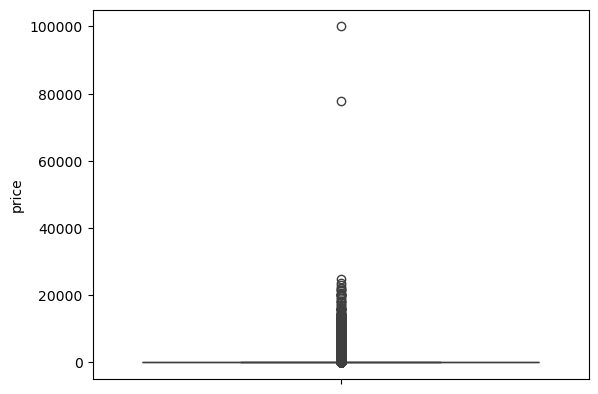

In [31]:
# I cannot see anything. 
sns.boxplot(data=num.price)
plt.show()

## Part 3: Unpacking Product Ratings

Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

**Measures of Centrality:**

Calculate the mean, median, and mode for the rating of products.

How do customers generally rate products? Is there a common trend?

**Measures of Dispersion:**

Determine the variance, standard deviation, and interquartile range for product rating.

Are the ratings consistent, or is there a wide variation in customer feedback?

**Shape of the Distribution:**

Calculate the skewness and kurtosis for the rating column.

Are the ratings normally distributed, or do they lean towards higher or lower values?

**Visualizations:**

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [32]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [33]:
def categorize_starts (stars):
    if stars >= 4.5 and stars <= 5.0:
        return 'Excellent'
    elif stars >= 3.5 and stars < 4.5:
        return 'Very Good'
    elif stars >= 2.5 and stars < 3.5:
        return 'Good'
    elif stars >= 1.5 and stars < 2.5:
        return 'Fair'
    else:
        return 'Bad'
df['rating'] = df['stars'].apply(categorize_starts)

In [34]:
df.sample(10)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category,rating
437012,469541,B0C4MDS8Z5,New Era MLB The League 9FORTY 2-Tone Adjustabl...,4.6,36,42.79,False,0,Sports & Outdoors,Excellent
943512,1028443,B0BYD2NL2L,Hcclijo Summer Mesh Thin Multi Pocket Vest For...,0.0,0,58.39,False,0,Sports & Outdoors,Bad
1208413,1334201,B089VRG17M,"GJZM 26 Inch Mountain Bikes, High-carbon Steel...",0.0,0,960.99,False,0,Sports & Outdoors,Bad
1526663,1714366,B08QHZF2BN,N-B Women Snow Pant Outdoor Sports Wear Specia...,0.0,0,40.99,False,0,Sports & Outdoors,Bad
1171023,1295002,B0B9BJ2829,"ENPAP Men's GPS Smart Watch,Fitness Tracker of...",0.0,0,682.79,False,0,Smartwatches,Bad
803716,866718,B07YCP9XM8,Mens Vintage Blue Beanie Hat,4.7,5,15.00,False,0,Ski Clothing,Excellent
2188621,2534392,B0053TQ44O,TOAOB 100pairs Earring Safety Backs Clear Rubb...,4.4,1213,3.29,False,200,Arts & Crafts,Very Good
1910195,2141981,B0C2CRMP99,"Wi-Fi Weather Station with Solar, Indoor/Outdo...",0.0,0,228.34,False,0,Garden Storage & Housing,Bad
1182321,1306910,B00F5VSQN2,Power Supply Replacement for Korg Gt-3 Adapter...,0.0,0,5.99,False,0,Piano & Keyboard,Bad
1286722,1423125,B0BY9D5JF1,Jikoiuty 3 Pcs Removable Surfboard Fin Plug fo...,0.0,0,12.11,False,0,Sports & Outdoors,Bad


In [35]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
rating                object
dtype: object

In [36]:
rating1 = df['rating'].value_counts().reset_index()
rating1

,rating,count
0,Bad,1234378
1,Very Good,583264
2,Excellent,564569
3,Good,53326
4,Fair,8114


In [37]:
rate = round(df.rating.value_counts('Bad') * 100, 2).reset_index()

In [38]:
rate_merge = pd.merge(rating1, rate, on='rating')
rate_merge

,rating,count,proportion
0,Bad,1234378,50.51
1,Very Good,583264,23.87
2,Excellent,564569,23.10
3,Good,53326,2.18
4,Fair,8114,0.33


In [39]:
def categorize_rating (i):
    if i == 'Excellent':
        return 5
    elif == 'Very Good':
        return 4
    elif == 'Good':
        return 3
    elif == 'Fair':
        return 2
    else:
        return 1
df['value'] = df['rating'].apply(categorize_rating)

SyntaxError: invalid syntax (1904147793.py, line 4)

In [41]:
def categorize_rating(i):
    if i == 'Excellent':
        return 5
    elif i == 'Very Good':
        return 4
    elif i == 'Good':
        return 3
    elif i == 'Fair':
        return 2
    else:  # This covers 'Bad' or any other category
        return 1
df['value'] = df['rating'].apply(categorize_rating)

In [42]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category,rating,value
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers,Excellent,5
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers,Excellent,5
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers,Excellent,5
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers,Excellent,5
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers,Excellent,5
...,...,...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing,Bad,1
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing,Bad,1
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing,Bad,1
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing,Very Good,4


In [43]:
df['value'].mean()

2.687161546391035

In [44]:
df['value'].median()

1.0

In [45]:
df['value'].mode()

0    1
Name: value, dtype: int64

In [46]:
df['value'].var()

3.0888265557721524

In [47]:
df['value'].std()

1.7575057768815874

In [48]:
df['value'].quantile([0.5])

0.5    1.0
Name: value, dtype: float64

In [49]:
# In this case we do have inconsistency and variation pointing to a disparity in customer satisfaction. Positively skewed.

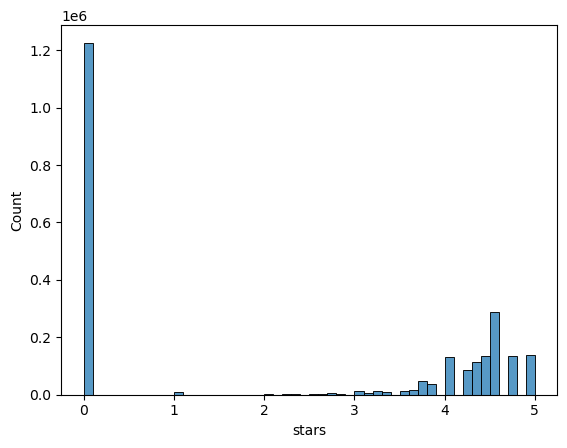

In [50]:
sns.histplot(df.stars, bins=50)
plt.show()

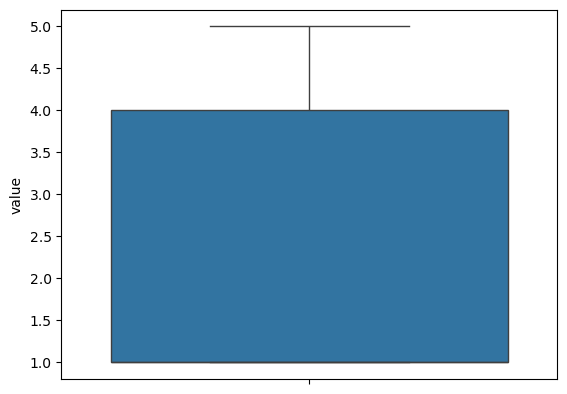

In [51]:
sns.boxplot(data=df.value)
plt.show()

In [52]:
# There is a longer tail on the positively skewed. But not for too mcuh. 
df.stars.skew().round(2)

0.08

In [53]:
# Negative Kurtosis. 
df.stars.kurtosis().round(2) 

-1.93